In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from matplotlib import rc
rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
rc('text', usetex=True)

In [17]:
df1 = pd.read_csv("globular_clusters.csv")
df1 = df1[0:-3]
harris_p1 = pd.read_csv('HarrisPartI.csv')
harris_p2 = pd.read_csv('HarrisPartII.csv')
harris_p3 = pd.read_csv('HarrisPartIII.csv')

In [18]:
R_gc = pd.to_numeric(harris_p1['R_gc'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
name = harris_p1['ID']
R_Sun = pd.to_numeric(harris_p1['R_Sun'],errors='coerce')
sig_v = pd.to_numeric(harris_p3['sig_v'],errors='coerce')
v_r = pd.to_numeric(harris_p3['v_r'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
M_V = pd.to_numeric(harris_p2['M_V,t'],errors='coerce')
v_LSR = pd.to_numeric(harris_p3['v_LSR'],errors='coerce')
L = pd.to_numeric(harris_p1['L'],errors='coerce')
B = pd.to_numeric(harris_p1['B'],errors='coerce')
r_h = pd.to_numeric(harris_p3['r_h'],errors='coerce')
l = L*np.pi/180
b = B*np.pi/180
V0 = 220
v_GSR = v_LSR + V0*np.sin(l)*np.cos(b)

In [19]:
G = 4.3009172706*10**(-6) # kpc * (km/s)^2 / M_o
R = r_h*np.pi/(60*180)*R_Sun # kpc
M = sig_v**2*R/G # M_o
Mlog = np.log10(M)
Rlog = np.log10(R_gc)
vlog = np.log10(abs(v_GSR)/sig_v)
mask = np.isfinite(Rlog) & np.isfinite(vlog) & np.isfinite(Mlog)

0.9516129032258065


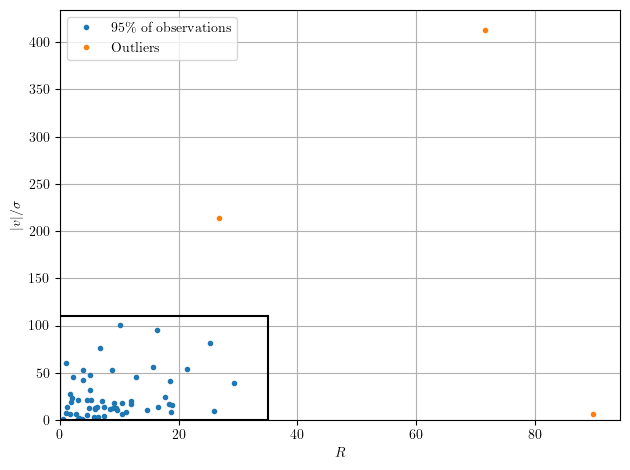

In [52]:
new_mask = (10**Rlog < 35) & (10**vlog < 110)
print(len(vlog[mask][new_mask])/len(vlog[mask][new_mask]+vlog[mask][~new_mask]))

plt.figure()
plt.plot((10**Rlog)[new_mask],(10**vlog)[new_mask],'.',label = r'$95\%$ of observations')
plt.plot((10**Rlog)[~new_mask],(10**vlog)[~new_mask],'.',label=r'Outliers')
plt.xlabel(r'$R$')
plt.ylabel(r'$|v|/\sigma$')
s = np.linspace(0,35,100)
t = np.linspace(0,110,100)
plt.plot(s,s*0,color='black')
plt.plot(s,s*0+110,color='black')
plt.plot(t*0,t,color='black')
plt.plot(t*0+35,t,color='black')
plt.grid()
plt.tight_layout()
plt.legend()
plt.xlim(0)
plt.ylim(0)
plt.show()

In [53]:
print(name[mask][~new_mask])

12     NGC 2419
45       Pal 14
155      Pal 13
Name: ID, dtype: object
